In [ ]:
pip install numpy matplotlib scikit-learn

In [ ]:
!pip install tensorflow

In [ ]:
!pip install keras

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import time

In [ ]:
# Load MNIST dataset
from keras.datasets import mnist as keras_mnist
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = keras_mnist.load_data()
X = np.concatenate([X_train_raw.reshape(-1, 784), X_test_raw.reshape(-1, 784)])
y = np.concatenate([y_train_raw, y_test_raw])

# Convert to proper types
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)

print(f"Dataset loaded: {X.shape[0]} samples, {X.shape[1]} features")

Dataset loaded: 70000 samples, 784 features


In [ ]:
# 1. Normalization: Scale pixel values to [0, 1]
X_normalized = X / 255.0

# 2. Centering: Subtract mean (alignment)
X_centered = X_normalized - np.mean(X_normalized, axis=0)

# 3. Standardization: Scale to unit variance
scaler = StandardScaler()
X_preprocessed = scaler.fit_transform(X_centered)
print("✓ Standardized data (unit variance)")

✓ Standardized data (unit variance)


In [ ]:
# 4. Train-test split (80-20)
X_train, X_test, y_train, y_test = train_test_split(
    X_preprocessed, y, test_size=0.2, random_state=42, stratify=y
)
print(f"✓ Split data: {X_train.shape[0]} training, {X_test.shape[0]} testing samples")


✓ Split data: 56000 training, 14000 testing samples


In [ ]:
# Define dimensionalities to test
dimensions = [2, 3, 4, 5, 6, 7, 8, 9]

# Storage for results
results = {
    'dims': [],
    'pca_accuracy': [],
    'lda_accuracy': [],
    'pca_time': [],
    'lda_time': []
}

# k-NN classifier parameters
k_neighbors = 3
print(f"Using k-NN classifier with k={k_neighbors}")

print("\nBenchmarking performance across dimensions...")
print("-" * 70)

for dim in dimensions:
    print(f"\nDimension: {dim}")

    # --- PCA Dimensionality Reduction ---
    start_time = time.time()

    pca = PCA(n_components=dim, random_state=42)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    # Train k-NN on PCA-reduced data
    knn_pca = KNeighborsClassifier(n_neighbors=k_neighbors)
    knn_pca.fit(X_train_pca, y_train)
    y_pred_pca = knn_pca.predict(X_test_pca)

    pca_acc = accuracy_score(y_test, y_pred_pca)
    pca_time = time.time() - start_time

    print(f"  PCA: Accuracy = {pca_acc:.4f}, Time = {pca_time:.2f}s")

    # --- LDA Dimensionality Reduction ---
    # LDA can reduce to at most (n_classes - 1) dimensions
    lda_dim = min(dim, 9)  # MNIST has 10 classes (0-9)

    start_time = time.time()

    lda = LDA(n_components=lda_dim)
    X_train_lda = lda.fit_transform(X_train, y_train)
    X_test_lda = lda.transform(X_test)

    # Train k-NN on LDA-reduced data
    knn_lda = KNeighborsClassifier(n_neighbors=k_neighbors)
    knn_lda.fit(X_train_lda, y_train)
    y_pred_lda = knn_lda.predict(X_test_lda)

    lda_acc = accuracy_score(y_test, y_pred_lda)
    lda_time = time.time() - start_time

    print(f"  LDA: Accuracy = {lda_acc:.4f}, Time = {lda_time:.2f}s (dim={lda_dim})")

    # Store results
    results['dims'].append(dim)
    results['pca_accuracy'].append(pca_acc)
    results['lda_accuracy'].append(lda_acc)
    results['pca_time'].append(pca_time)
    results['lda_time'].append(lda_time)

print("\n" + "=" * 70)
print("BENCHMARK COMPLETE")
print("=" * 70)

Using k-NN classifier with k=3

Benchmarking performance across dimensions...
----------------------------------------------------------------------

Dimension: 2
  PCA: Accuracy = 0.3083, Time = 1.22s
  LDA: Accuracy = 0.4918, Time = 11.39s (dim=2)

Dimension: 3
  PCA: Accuracy = 0.4943, Time = 1.37s
  LDA: Accuracy = 0.6997, Time = 12.14s (dim=3)

Dimension: 4
  PCA: Accuracy = 0.6439, Time = 1.41s
  LDA: Accuracy = 0.8006, Time = 12.07s (dim=4)

Dimension: 5
  PCA: Accuracy = 0.7253, Time = 1.40s
  LDA: Accuracy = 0.8185, Time = 11.48s (dim=5)

Dimension: 6
  PCA: Accuracy = 0.8205, Time = 1.76s
  LDA: Accuracy = 0.8540, Time = 12.29s (dim=6)

Dimension: 7
  PCA: Accuracy = 0.8370, Time = 2.33s
  LDA: Accuracy = 0.8817, Time = 12.40s (dim=7)

Dimension: 8
  PCA: Accuracy = 0.8698, Time = 2.38s
  LDA: Accuracy = 0.9014, Time = 13.85s (dim=8)

Dimension: 9
  PCA: Accuracy = 0.8812, Time = 3.73s
  LDA: Accuracy = 0.9100, Time = 11.68s (dim=9)

BENCHMARK COMPLETE


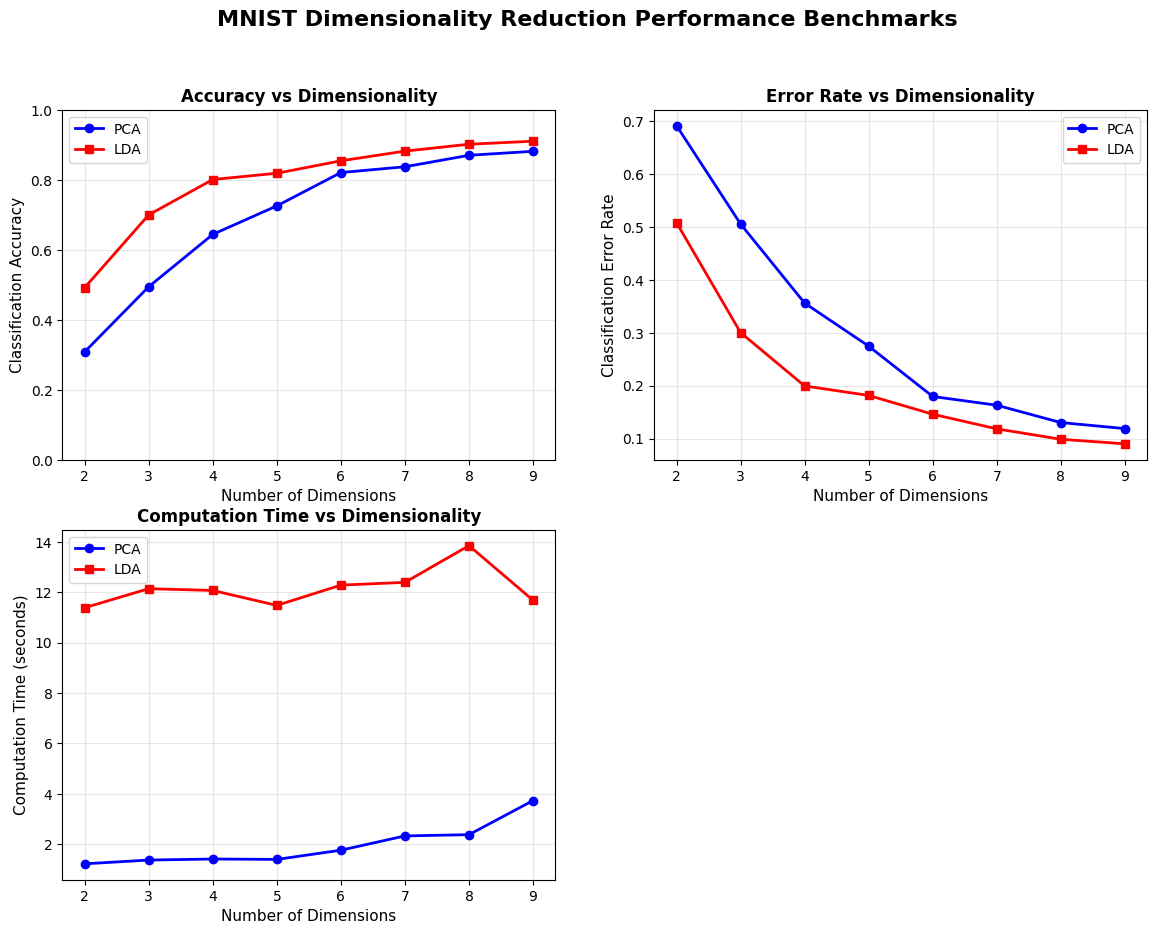

In [ ]:
# --- Visualization ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('MNIST Dimensionality Reduction Performance Benchmarks',
             fontsize=16, fontweight='bold')

# Plot 1: Accuracy vs Dimensionality
axes[0, 0].plot(results['dims'], results['pca_accuracy'],
                marker='o', linewidth=2, label='PCA', color='blue')
axes[0, 0].plot(results['dims'], results['lda_accuracy'],
                marker='s', linewidth=2, label='LDA', color='red')
axes[0, 0].set_xlabel('Number of Dimensions', fontsize=11)
axes[0, 0].set_ylabel('Classification Accuracy', fontsize=11)
axes[0, 0].set_title('Accuracy vs Dimensionality', fontsize=12, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_ylim([0, 1])

# Plot 2: Error Rate vs Dimensionality
pca_error = [1 - acc for acc in results['pca_accuracy']]
lda_error = [1 - acc for acc in results['lda_accuracy']]
axes[0, 1].plot(results['dims'], pca_error,
                marker='o', linewidth=2, label='PCA', color='blue')
axes[0, 1].plot(results['dims'], lda_error,
                marker='s', linewidth=2, label='LDA', color='red')
axes[0, 1].set_xlabel('Number of Dimensions', fontsize=11)
axes[0, 1].set_ylabel('Classification Error Rate', fontsize=11)
axes[0, 1].set_title('Error Rate vs Dimensionality', fontsize=12, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Computation Time vs Dimensionality
axes[1, 0].plot(results['dims'], results['pca_time'],
                marker='o', linewidth=2, label='PCA', color='blue')
axes[1, 0].plot(results['dims'], results['lda_time'],
                marker='s', linewidth=2, label='LDA', color='red')
axes[1, 0].set_xlabel('Number of Dimensions', fontsize=11)
axes[1, 0].set_ylabel('Computation Time (seconds)', fontsize=11)
axes[1, 0].set_title('Computation Time vs Dimensionality', fontsize=12, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Summary Statistics Table
axes[1, 1].axis('off')
summary_text = f"""
PERFORMANCE SUMMARY
{'=' * 40}

Best PCA Accuracy: {max(results['pca_accuracy']):.4f}
  at {results['dims'][results['pca_accuracy'].index(max(results['pca_accuracy']))]} dimensions

Best LDA Accuracy: {max(results['lda_accuracy']):.4f}
  at {results['dims'][results['lda_accuracy'].index(max(results['lda_accuracy']))]} dimensions

PCA Accuracy Range: {min(results['pca_accuracy']):.4f} - {max(results['pca_accuracy']):.4f}
LDA Accuracy Range: {min(results['lda_accuracy']):.4f} - {max(results['lda_accuracy']):.4f}

Original Dimensionality: 784
Samples Used: {X.shape[0]}
k-NN Neighbors: {k_neighbors}
"""

In [ ]:

axes[1, 1].text(0.1, 0.5, summary_text, fontsize=10, family='monospace',
                verticalalignment='center')

plt.tight_layout()
plt.savefig('mnist_dimensionality_benchmark.png', dpi=300, bbox_inches='tight')
print("\n✓ Plots saved as 'mnist_dimensionality_benchmark.png'")
plt.show()

# Print detailed results table
print("\n" + "=" * 70)
print("DETAILED RESULTS TABLE")
print("=" * 70)
print(f"{'Dims':<8} {'PCA Acc':<12} {'PCA Error':<12} {'LDA Acc':<12} {'LDA Error':<12}")
print("-" * 70)
for i in range(len(results['dims'])):
    print(f"{results['dims'][i]:<8} "
          f"{results['pca_accuracy'][i]:<12.4f} "
          f"{1-results['pca_accuracy'][i]:<12.4f} "
          f"{results['lda_accuracy'][i]:<12.4f} "
          f"{1-results['lda_accuracy'][i]:<12.4f}")
print("=" * 70)


✓ Plots saved as 'mnist_dimensionality_benchmark.png'


<Figure size 640x480 with 0 Axes>


DETAILED RESULTS TABLE
Dims     PCA Acc      PCA Error    LDA Acc      LDA Error   
----------------------------------------------------------------------
2        0.3083       0.6917       0.4918       0.5082      
3        0.4943       0.5057       0.6997       0.3003      
4        0.6439       0.3561       0.8006       0.1994      
5        0.7253       0.2747       0.8185       0.1815      
6        0.8205       0.1795       0.8540       0.1460      
7        0.8370       0.1630       0.8817       0.1183      
8        0.8698       0.1302       0.9014       0.0986      
9        0.8812       0.1188       0.9100       0.0900      
